# Customer Churn Prediction & Customer Experience Analytics
**Portfolio project | Python · Machine Learning · Customer Retention**

## Business objective
Identify customer profiles associated with cancellation, estimate churn risk, and translate model outputs into prioritization ideas for a Customer Experience or Retention team.

**Important scope note:** the source data describes telecom customers, services, contracts, and charges. It does not directly contain complaint logs, delivery failures, or customer satisfaction survey responses. Therefore, this project will not claim to identify actual service complaints. Those signals would require additional data.

## Project workflow
1. Load and validate the four source tables.
2. Join them into one customer-level analytical dataset.
3. Explore churn patterns and customer segments.
4. Train and compare classification models using a leakage-safe pipeline.
5. Evaluate model quality and review influential features.
6. Translate findings into practical retention actions and limitations.

**Data provenance:** this notebook expects the original TripleTen-style files `contract.csv`, `personal.csv`, `internet.csv`, and `phone.csv` in the same folder. Confirm the dataset source and version before publishing the project.


## 1. Setup and load data

In [22]:

# CUSTOMER CHURN — DATA LOADING
# Proyecto Customer Experience & Retention Analytics

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 1. CONFIGURATION
RANDOM_STATE = 42

DATA_DIR = Path(
    r"D:\COMMERCIAL EXCELLENCE\Proyectos independientes\Customer_Churn_CX"
)

# 2. VALIDATE FILES
required_files = [
    "contract.csv",
    "personal.csv",
    "internet.csv",
    "phone.csv"
]

print("CUSTOMER CHURN PROJECT")
print("=" * 45)
print("Data folder:", DATA_DIR)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"The folder does not exist: {DATA_DIR}\n"
        "Verify the folder location in VS Code."
    )

missing_files = [
    filename
    for filename in required_files
    if not (DATA_DIR / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing CSV files: {missing_files}\n"
        f"Files currently in folder: "
        f"{[f.name for f in DATA_DIR.iterdir()]}"
    )

# 3. LOAD DATA
df_contract = pd.read_csv(DATA_DIR / "contract.csv")
df_personal = pd.read_csv(DATA_DIR / "personal.csv")
df_internet = pd.read_csv(DATA_DIR / "internet.csv")
df_phone = pd.read_csv(DATA_DIR / "phone.csv")

# 4. CONFIRM SUCCESSFUL LOADING
datasets = {
    "Contract": df_contract,
    "Personal": df_personal,
    "Internet": df_internet,
    "Phone": df_phone
}

print("\nDATASETS LOADED SUCCESSFULLY")
print("=" * 45)

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")

print("\nContract dataset preview:")
display(df_contract.head())

print("\nPersonal dataset preview:")
display(df_personal.head())

print("\nInternet dataset preview:")
display(df_internet.head())

print("\nPhone dataset preview:")
display(df_phone.head())



CUSTOMER CHURN PROJECT
Data folder: D:\COMMERCIAL EXCELLENCE\Proyectos independientes\Customer_Churn_CX

DATASETS LOADED SUCCESSFULLY
Contract: 7,043 rows × 8 columns
Personal: 7,043 rows × 5 columns
Internet: 5,517 rows × 8 columns
Phone: 6,361 rows × 2 columns

Contract dataset preview:


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65



Personal dataset preview:


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No



Internet dataset preview:


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No



Phone dataset preview:


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


## 2. Data validation and integration

In [23]:
# Normalize column names to simplify downstream analysis.
def normalize_columns(frame):
    frame = frame.copy()
    frame.columns = (
        frame.columns.astype(str).str.strip().str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )
    return frame

df_contract, df_personal, df_internet, df_phone = [
    normalize_columns(df) for df in
    [df_contract, df_personal, df_internet, df_phone]
]

# Inspect key columns before joining.
for name, frame in {
    "contract": df_contract, "personal": df_personal,
    "internet": df_internet, "phone": df_phone
}.items():
    print(f"\n{name.upper()} columns:")
    print(frame.columns.tolist())

# Identify the customer key using common names.
def find_customer_key(frame):
    candidates = ["customer_id", "customerid", "customer"]
    for col in candidates:
        if col in frame.columns:
            return col
    raise KeyError(f"No customer ID column found in columns: {frame.columns.tolist()}")

for frame in [df_contract, df_personal, df_internet, df_phone]:
    key = find_customer_key(frame)
    if key != "customer_id":
        frame.rename(columns={key: "customer_id"}, inplace=True)

# Ensure each table has at most one row per customer before joining.
for name, frame in {
    "contract": df_contract, "personal": df_personal,
    "internet": df_internet, "phone": df_phone
}.items():
    duplicate_count = frame["customer_id"].duplicated().sum()
    print(f"{name}: duplicate customer IDs = {duplicate_count:,}")

data = df_contract.merge(df_personal, on="customer_id", how="left", validate="one_to_one")
data = data.merge(df_internet, on="customer_id", how="left", validate="one_to_one")
data = data.merge(df_phone, on="customer_id", how="left", validate="one_to_one")

print("Integrated dataset:", data.shape)
display(data.head())



CONTRACT columns:
['customerid', 'begindate', 'enddate', 'type', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges']

PERSONAL columns:
['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents']

INTERNET columns:
['customerid', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies']

PHONE columns:
['customerid', 'multiplelines']
contract: duplicate customer IDs = 0
personal: duplicate customer IDs = 0
internet: duplicate customer IDs = 0
phone: duplicate customer IDs = 0
Integrated dataset: (7043, 20)


,customer_id,begindate,enddate,type,paperlessbilling,paymentmethod,monthlycharges,totalcharges,gender,seniorcitizen,partner,dependents,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,multiplelines
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,NaN
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,NaN
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No


## 3. Define the churn target

Customers: 7043
Churned customers: 1869
Churn rate: 26.5%


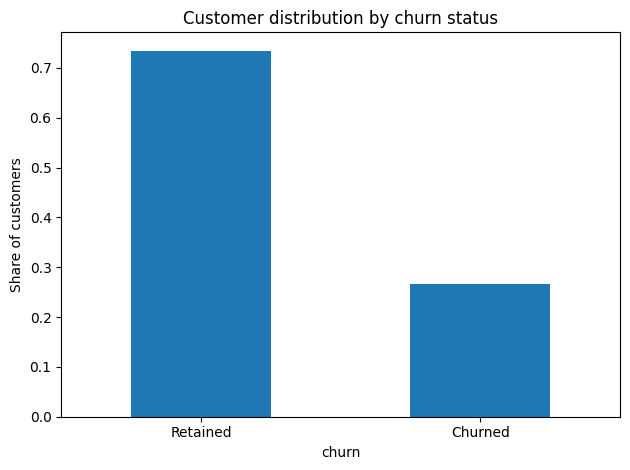

In [24]:
# 3. Define churn target

# Normalize column names
data.columns = data.columns.str.strip().str.lower()

# Identify the cancellation date column
possible_columns = ["end_date", "enddate", "fecha_baja", "fecha_cancelacion"]
churn_column = next(
    (col for col in possible_columns if col in data.columns),
    None
)

if churn_column is None:
    print("Available columns:", data.columns.tolist())
    raise KeyError(
        "No cancellation-date column found. Check the available columns above."
    )

# Create churn target:
# A cancellation date means churn; empty or 'No' means retained.
end_date = data[churn_column].astype("string").str.strip()

data["churn"] = (
    end_date.notna()
    & end_date.ne("")
    & end_date.str.lower().ne("no")
).astype(int)

print("Customers:", len(data))
print("Churned customers:", int(data["churn"].sum()))
print("Churn rate: {:.1%}".format(data["churn"].mean()))

ax = (
    data["churn"]
    .value_counts(normalize=True)
    .sort_index()
    .rename(index={0: "Retained", 1: "Churned"})
    .plot(
        kind="bar",
        rot=0,
        title="Customer distribution by churn status"
    )
)

ax.set_ylabel("Share of customers")
plt.tight_layout()
plt.show()

## 4. Exploratory analysis: customer and contract patterns

In [25]:
# Numeric summary and missingness
display(data.describe(include="all").T)
missing_summary = data.isna().mean().mul(100).sort_values(ascending=False)
display(missing_summary[missing_summary > 0].rename("missing_pct").to_frame().head(20))

# Churn rate by available categorical variables.
candidate_cats = [
    "type", "internet_service", "payment_method", "paperless_billing",
    "senior_citizen", "partner", "dependents", "tech_support",
    "online_security", "multiple_lines"
]
available_cats = [c for c in candidate_cats if c in data.columns]

for col in available_cats[:8]:
    summary = data.groupby(col, dropna=False)["churn"].agg(["mean", "count"]).sort_values("mean", ascending=False)
    summary["churn_rate_pct"] = (summary["mean"] * 100).round(1)
    display(summary[["count", "churn_rate_pct"]].sort_values("churn_rate_pct", ascending=False))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
begindate,7043,77,2014-02-01,366,NaN,NaN,NaN,NaN,NaN,NaN,NaN
enddate,7043,5,No,5174,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,7043,3,Month-to-month,3875,NaN,NaN,NaN,NaN,NaN,NaN,NaN
paperlessbilling,7043,2,Yes,4171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
paymentmethod,7043,4,Electronic check,2365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthlycharges,7043.0,NaN,NaN,NaN,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
totalcharges,7043,6531,20.2,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seniorcitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0


,missing_pct
techsupport,21.666903
streamingtv,21.666903
streamingmovies,21.666903
deviceprotection,21.666903
internetservice,21.666903
onlinebackup,21.666903
onlinesecurity,21.666903
multiplelines,9.683374


,count,churn_rate_pct
type,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


,count,churn_rate_pct
partner,,
No,3641,33.0
Yes,3402,19.7


,count,churn_rate_pct
dependents,,
No,4933,31.3
Yes,2110,15.5


## 5. Prepare modeling data

In [26]:

# 5. Prepare modeling data

# Remove identifiers, target columns, and cancellation-date variants
drop_cols = [
    col for col in data.columns
    if col.strip().lower() in [
        "customer_id",
        "end_date",
        "enddate",
        "churn"
    ]
]

X = data.drop(columns=drop_cols).copy()
y = data["churn"].copy()

print("Removed columns:", drop_cols)
print("Rows:", f"{len(X):,}")
print("Predictors:", X.shape[1])
print("Churn rate:", f"{y.mean():.2%}")

# Convert numeric-looking columns when appropriate
for col in X.columns:
    if X[col].dtype == "object":
        converted = pd.to_numeric(X[col], errors="coerce")
        non_null_original = X[col].notna().sum()

        if (
            non_null_original > 0
            and converted.notna().sum() / non_null_original >= 0.9
        ):
            X[col] = converted

# Identify numeric and categorical features
numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Remaining columns:", X.columns.tolist())

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nData preparation completed successfully.")
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))



Removed columns: ['customer_id', 'enddate', 'churn']
Rows: 7,043
Predictors: 18
Churn rate: 26.54%
Numeric features: 3
Categorical features: 15
Remaining columns: ['begindate', 'type', 'paperlessbilling', 'paymentmethod', 'monthlycharges', 'totalcharges', 'gender', 'seniorcitizen', 'partner', 'dependents', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'multiplelines']

Data preparation completed successfully.
Training rows: 5282
Test rows: 1761


In [27]:
# Diagnostic check: target distribution and possible leakage

print("Target distribution:")
print(y.value_counts(dropna=False))

print("\nChurn rate:")
print(round(y.mean(), 4))

print("\nPotentially suspicious columns:")
for col in X.columns:
    unique_values = X[col].nunique(dropna=False)
    if unique_values <= 10:
        print(f"{col}: {X[col].value_counts(dropna=False).to_dict()}")

print("\nCheck whether any feature perfectly matches churn:")
for col in X.columns:
    if X[col].nunique(dropna=False) > 1:
        match_rate = (
            X[col].astype(str).reset_index(drop=True)
            == y.astype(str).reset_index(drop=True)
        ).mean()
        if match_rate == 1.0:
            print(f"Possible leakage: {col}")

Target distribution:
churn
0    5174
1    1869
Name: count, dtype: int64

Churn rate:
0.2654

Potentially suspicious columns:
type: {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
paperlessbilling: {'Yes': 4171, 'No': 2872}
paymentmethod: {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (automatic)': 1544, 'Credit card (automatic)': 1522}
gender: {'Male': 3555, 'Female': 3488}
seniorcitizen: {0: 5901, 1: 1142}
partner: {'No': 3641, 'Yes': 3402}
dependents: {'No': 4933, 'Yes': 2110}
internetservice: {'Fiber optic': 3096, 'DSL': 2421, nan: 1526}
onlinesecurity: {'No': 3498, 'Yes': 2019, nan: 1526}
onlinebackup: {'No': 3088, 'Yes': 2429, nan: 1526}
deviceprotection: {'No': 3095, 'Yes': 2422, nan: 1526}
techsupport: {'No': 3473, 'Yes': 2044, nan: 1526}
streamingtv: {'No': 2810, 'Yes': 2707, nan: 1526}
streamingmovies: {'No': 2785, 'Yes': 2732, nan: 1526}
multiplelines: {'No': 3390, 'Yes': 2971, nan: 682}

Check whether any feature perfectly matches churn:


## 6. Train and compare baseline models

In [28]:
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

pipelines = {
    name: Pipeline(steps=[("preprocess", preprocessor), ("model", model)])
    for name, model in models.items()
}

results = []
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline[-1], "predict_proba") else None
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, proba) if proba is not None else np.nan
    })

results_df = pd.DataFrame(results).sort_values("roc_auc", ascending=False)
display(results_df.round(3))


,model,accuracy,precision,recall,f1,roc_auc
2,Random Forest,0.792,0.587,0.730,0.651,0.862
1,Logistic Regression,0.756,0.526,0.807,0.637,0.851
0,Dummy baseline,0.735,0.000,0.000,0.000,0.500


## 7. Evaluate the selected model

Selected model: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.81      0.85      1294
           1       0.59      0.73      0.65       467

    accuracy                           0.79      1761
   macro avg       0.74      0.77      0.75      1761
weighted avg       0.81      0.79      0.80      1761



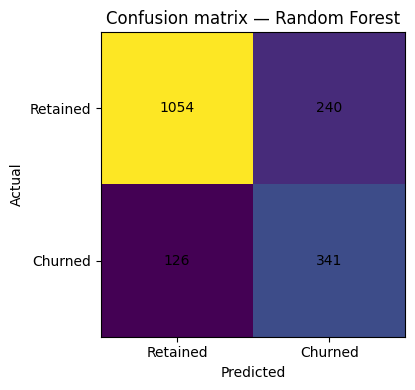

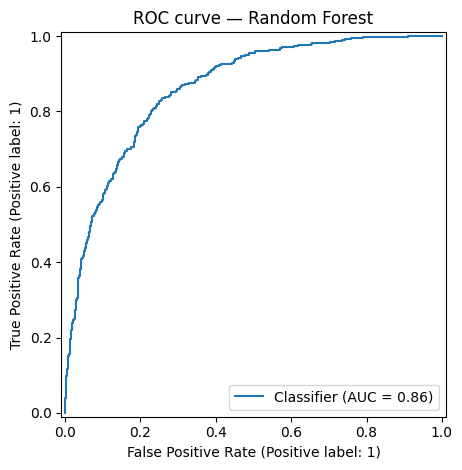

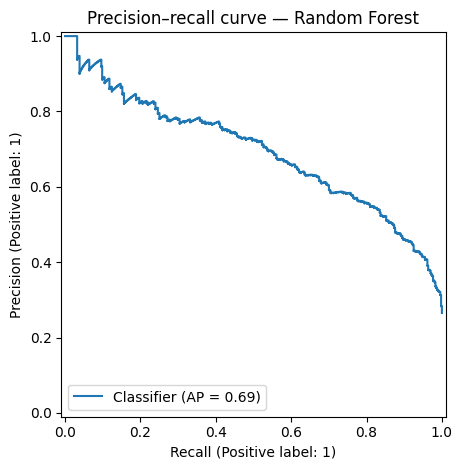

In [29]:
# Select by ROC-AUC; in a real retention operation, the final choice should also consider
# recall, precision, intervention capacity, and the cost of false positives/negatives.
best_name = results_df.iloc[0]["model"]
best_model = pipelines[best_name]
best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_pred, zero_division=0))

cm = confusion_matrix(y_test, best_pred)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm)
ax.set_title(f"Confusion matrix — {best_name}")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_xticks([0, 1], labels=["Retained", "Churned"])
ax.set_yticks([0, 1], labels=["Retained", "Churned"])
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, best_proba)
plt.title(f"ROC curve — {best_name}")
plt.tight_layout()
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, best_proba)
plt.title(f"Precision–recall curve — {best_name}")
plt.tight_layout()
plt.show()


## 8. Create a risk-prioritization view

In [30]:
# These are model-based risk estimates, not proof that a customer will cancel.
risk_view = X_test.copy()
risk_view["actual_churn"] = y_test.values
risk_view["predicted_churn_probability"] = best_proba
risk_view["risk_band"] = pd.cut(
    risk_view["predicted_churn_probability"],
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Lower", "Medium", "Higher"]
)

risk_summary = risk_view.groupby("risk_band", observed=False).agg(
    customers=("predicted_churn_probability", "size"),
    avg_predicted_risk=("predicted_churn_probability", "mean"),
    observed_churn_rate=("actual_churn", "mean")
).reset_index()
display(risk_summary.round(3))

display(
    risk_view.sort_values("predicted_churn_probability", ascending=False)
    .head(20)
)


,risk_band,customers,avg_predicted_risk,observed_churn_rate
0,Lower,833,0.124,0.050
1,Medium,487,0.443,0.283
2,Higher,441,0.750,0.651


,begindate,type,paperlessbilling,paymentmethod,monthlycharges,totalcharges,gender,seniorcitizen,partner,dependents,...,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,multiplelines,actual_churn,predicted_churn_probability,risk_band
6623,2019-09-01,Month-to-month,Yes,Electronic check,76.45,76.45,Male,1,No,No,...,No,No,No,No,No,No,Yes,1,0.959966,Higher
6633,2019-09-01,Month-to-month,Yes,Electronic check,74.50,74.50,Female,0,No,No,...,No,No,No,No,No,No,Yes,1,0.949186,Higher
3727,2019-07-01,Month-to-month,Yes,Electronic check,96.60,291.90,Female,0,No,No,...,No,No,No,No,Yes,Yes,Yes,1,0.948719,Higher
2194,2019-09-01,Month-to-month,Yes,Electronic check,79.50,79.50,Male,0,No,No,...,No,No,No,No,Yes,No,No,1,0.948507,Higher
4585,2019-11-01,Month-to-month,Yes,Electronic check,85.05,85.05,Female,1,No,No,...,No,No,No,No,No,Yes,Yes,1,0.947657,Higher
6495,2019-09-01,Month-to-month,Yes,Electronic check,69.65,69.65,Male,0,No,No,...,No,No,No,No,No,No,No,1,0.945354,Higher
1739,2019-09-01,Month-to-month,Yes,Electronic check,69.90,69.90,Male,0,No,No,...,No,No,No,No,No,No,No,1,0.945117,Higher
6488,2019-10-01,Month-to-month,Yes,Electronic check,69.50,69.50,Female,0,No,No,...,No,No,No,No,No,No,No,1,0.944115,Higher
5662,2019-10-01,Month-to-month,Yes,Electronic check,70.25,70.25,Female,0,No,No,...,No,No,No,No,No,No,No,1,0.941174,Higher
6866,2019-11-01,Month-to-month,Yes,Electronic check,95.45,95.45,Male,0,No,No,...,No,No,No,No,Yes,Yes,Yes,1,0.938964,Higher


## 9. Feature importance / drivers

,feature,importance_mean,importance_std
1,type,0.1184,0.0108
5,totalcharges,0.0438,0.0020
0,begindate,0.0260,0.0017
4,monthlycharges,0.0249,0.0019
10,internetservice,0.0092,0.0033
3,paymentmethod,0.0051,0.0016
16,streamingmovies,0.0043,0.0011
15,streamingtv,0.0034,0.0012
11,onlinesecurity,0.0032,0.0011
2,paperlessbilling,0.0029,0.0025


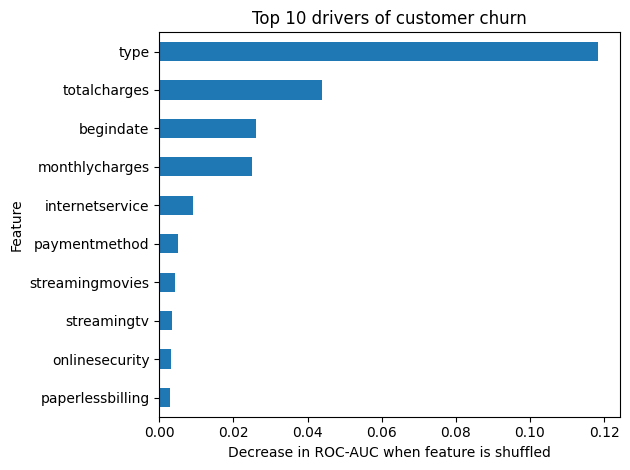

In [31]:
# 9. Feature importance / drivers

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate feature importance without parallel processing
perm = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Build results table
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance.head(15).round(4))

# Visualize the 10 most important features
top_features = importance.head(10).sort_values("importance_mean")

ax = top_features.plot(
    x="feature",
    y="importance_mean",
    kind="barh",
    legend=False,
    title="Top 10 drivers of customer churn"
)

ax.set_xlabel("Decrease in ROC-AUC when feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()


## 10. Business interpretation and Customer Experience action plan

### Key findings

- **Contract type is the strongest predictive feature.** Permutation importance shows that contract type contributes more to model performance than any other feature. Analyze churn rates by contract type to identify priority segments.
- **Customer charges are relevant predictors.** Total charges and monthly charges rank among the most influential features. Review pricing transparency and perceived value as potential areas for further investigation.
- **The high-risk segment warrants attention.** The model's high-risk group contains 441 customers, with an observed churn rate of 65.1% in the test set. This segment may be suitable for a targeted retention pilot.

### Recommended action plan

| Priority | Proposed action | KPI to monitor |
|---|---|---|
| High | Analyze churn rates by contract type and design segment-specific retention actions | Churn rate by contract type; save rate |
| High | Pilot proactive outreach for customers classified as high risk | Retention rate; save rate |
| Medium | Review pricing communication and perceived value among at-risk customers | Offer acceptance; revenue retained |
| Medium | Compare retention interventions against a control group | Incremental retention; cost per retained customer |

### Measurement and validation

These recommendations are hypotheses to test, not proven causes of churn. Measure the impact of retention actions through a controlled pilot and monitor customer retention, response rates, and intervention costs.

**Data limitations:** The dataset does not contain actual customer contacts, complaint records, response times, delivery incidents, or customer satisfaction (CSAT) survey results. Additional, properly documented operational data would be required to investigate direct relationships between service experience and customer cancellations.


## 11. Limitations and next steps

- The target is historical churn, not a guaranteed future outcome.
- The model's performance depends on the dataset version, data quality, and split.
- Feature importance describes predictive association, not causal impact.
- Thresholds should be chosen based on outreach capacity and the relative cost of missed churn versus unnecessary interventions.
- Retention effectiveness should be tested with a controlled pilot; model accuracy alone does not prove business impact.
- Before publication, verify all notebook outputs, document the dataset source and license, and define a measurable retention pilot to evaluate business impact.